In [1]:
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.dataset as ds
import pyarrow.compute as pc
import bearing_datasets as bd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

datasets = ["cwru", "paderborn", "ims", "xjtu_sy"]

metadata = {}

for name in datasets:
    ds = bd.open(name)
    metadata[name] = ds.metadata()

    print(f"\n{'=' * 50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'=' * 50}")

    print("Number of signals:", len(metadata[name]))
    print("Number of recordings:",
          metadata[name]["recording_id"].nunique())
    print("Columns:", metadata[name].columns.tolist())


DATASET: CWRU
Number of signals: 411
Number of recordings: 161
Columns: ['dataset', 'signal_id', 'recording_id', 'native_label', 'channel', 'sensor_location', 'fs', 'n_samples', 'fault_type', 'fault_location', 'sensor_at_fault', 'signal_file', 'signal_row_group', 'signal_row', 'quantity', 'unit', 'sensor_mounting', 'speed_rpm', 'load', 'load_unit', 'fault_origin', 'fault_size_mm', 'fault_severity', 'fault_severity_level', 'bearing_id', 'bearing_model', 'bpfo', 'bpfi', 'bsf', 'ftf', 'or_position', 'source_file']

DATASET: PADERBORN
Number of signals: 17920
Number of recordings: 2560
Columns: ['dataset', 'signal_id', 'recording_id', 'native_label', 'channel', 'sensor_location', 'fs', 'n_samples', 'fault_type', 'fault_location', 'sensor_at_fault', 'signal_file', 'signal_row_group', 'signal_row', 'quantity', 'unit', 'sensor_mounting', 'speed_rpm', 'load', 'load_unit', 'operating_condition', 'fault_origin', 'fault_severity', 'fault_severity_level', 'bearing_id', 'bearing_model', 'bpfo', 'b

In [2]:
PADERBORN_METADATA = r"C:\Users\adity\Desktop\AI\heavy\LLMprojects\BAllBearings\Data\paderborn\metadata.parquet"
PADERBORN_SIGNALS = r"C:\Users\adity\Desktop\AI\heavy\LLMprojects\BAllBearings\Data\paderborn\signals\part-float64.parquet"

IMS_METADATA = r"C:\Users\adity\Desktop\AI\heavy\LLMprojects\BAllBearings\Data\ims\metadata.parquet"

IMS_SIGNALS = r"C:\Users\adity\Desktop\AI\heavy\LLMprojects\BAllBearings\Data\ims\signals\part-float64.parquet"



In [3]:
import pandas as pd

# Paderborn
paderborn_metadata_df = pd.read_parquet(PADERBORN_METADATA)
paderborn_signals_df = pd.read_parquet(PADERBORN_SIGNALS)

# IMS
ims_metadata_df = pd.read_parquet(IMS_METADATA)
ims_signals_df = pd.read_parquet(IMS_SIGNALS)

## Working with PaderBorn Data first 
- model is essential for classification  


- Basic EDA

In [15]:
paderborn_metadata_df.head()

,dataset,signal_id,recording_id,native_label,channel,sensor_location,fs,n_samples,fault_type,fault_location,...,bearing_id,bearing_model,bpfo,bpfi,bsf,ftf,repetition,radial_force_n,damage,bearing_manufacturer
0,paderborn,N09_M07_F10_K001_1/force,N09_M07_F10_K001_1,K001,force,rig_shaft,4000,16008,normal,none,...,K001,6203,3.07057,4.92943,2.03567,0.38382,1,1000.0,none,IBU
1,paderborn,N09_M07_F10_K001_1/phase_current_1,N09_M07_F10_K001_1,K001,phase_current_1,motor_supply,64000,256823,normal,none,...,K001,6203,3.07057,4.92943,2.03567,0.38382,1,1000.0,none,IBU
2,paderborn,N09_M07_F10_K001_1/phase_current_2,N09_M07_F10_K001_1,K001,phase_current_2,motor_supply,64000,256823,normal,none,...,K001,6203,3.07057,4.92943,2.03567,0.38382,1,1000.0,none,IBU
3,paderborn,N09_M07_F10_K001_1/speed,N09_M07_F10_K001_1,K001,speed,rig_shaft,4000,16008,normal,none,...,K001,6203,3.07057,4.92943,2.03567,0.38382,1,1000.0,none,IBU
4,paderborn,N09_M07_F10_K001_1/temperature,N09_M07_F10_K001_1,K001,temperature,test_bearing,1,5,normal,none,...,K001,6203,3.07057,4.92943,2.03567,0.38382,1,1000.0,none,IBU


In [16]:
paderborn_signals_df.head()

,signal_id,signal
0,N09_M07_F10_K001_1/force,"[927.2627923316428, 919.9385735864832, 949.540..."
1,N09_M07_F10_K001_1/phase_current_1,"[-0.8726864618256157, -0.945697326035178, -1.0..."
2,N09_M07_F10_K001_1/phase_current_2,"[-1.1461328117425609, -1.2453173819895134, -1...."
3,N09_M07_F10_K001_1/speed,"[899.4742444862216, 899.4744255925016, 899.474..."
4,N09_M07_F10_K001_1/temperature,"[46.78039547689698, 47.00927731268321, 46.9879..."


In [17]:
paderborn_metadata_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17920 entries, 0 to 17919
Data columns (total 34 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   dataset               17920 non-null  object 
 1   signal_id             17920 non-null  object 
 2   recording_id          17920 non-null  object 
 3   native_label          17920 non-null  object 
 4   channel               17920 non-null  object 
 5   sensor_location       17920 non-null  object 
 6   fs                    17920 non-null  int64  
 7   n_samples             17920 non-null  int64  
 8   fault_type            17920 non-null  object 
 9   fault_location        17920 non-null  object 
 10  sensor_at_fault       17920 non-null  bool   
 11  signal_file           17920 non-null  object 
 12  signal_row_group      17920 non-null  int64  
 13  signal_row            17920 non-null  int64  
 14  quantity              17920 non-null  object 
 15  unit               

In [24]:
(paderborn_metadata_df['fault_location'][paderborn_metadata_df['fault_location'] == 'none'].count() / paderborn_metadata_df.shape[0]) * 100

np.float64(18.75)

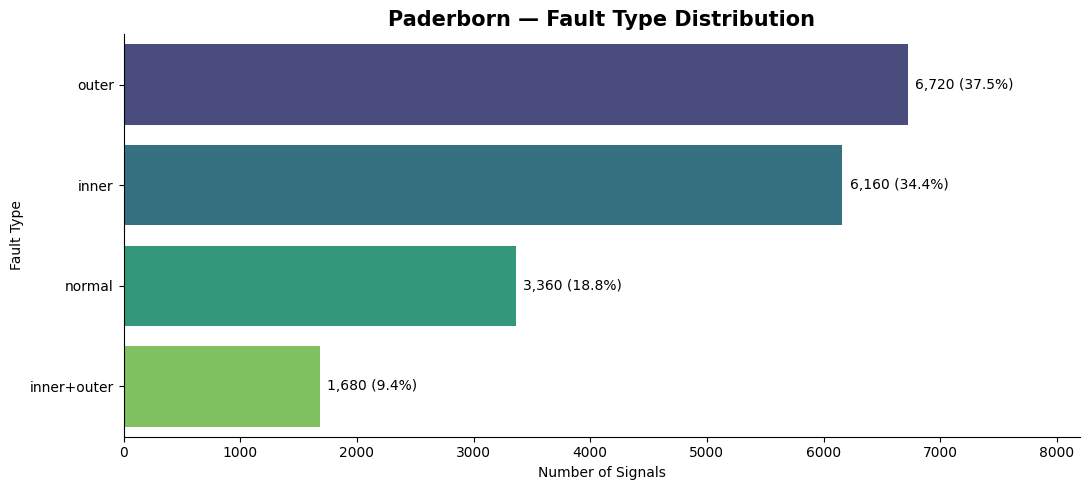

In [26]:

df = paderborn_metadata_df

counts = df["fault_type"].fillna("Unknown").value_counts()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    x=counts.values,
    y=counts.index,
    hue=counts.index,
    palette="viridis",
    legend=False,
    ax=ax
)

for i, (count, pct) in enumerate(zip(counts, percentages)):
    ax.text(
        count + counts.max() * 0.01,
        i,
        f"{count:,} ({pct:.1f}%)",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, counts.max() * 1.22)
ax.set_title("Paderborn — Fault Type Distribution", fontsize=15, weight="bold")
ax.set_xlabel("Number of Signals")
ax.set_ylabel("Fault Type")
sns.despine()
plt.tight_layout()
plt.show()


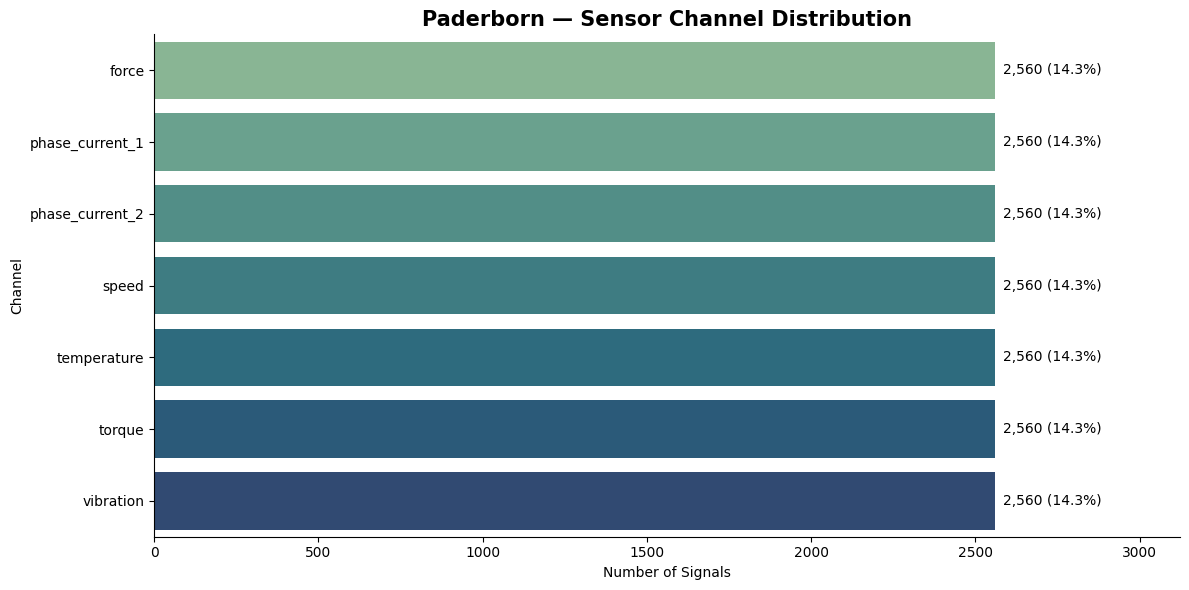

In [27]:

df = paderborn_metadata_df

counts = df["channel"].fillna("Unknown").value_counts()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=counts.values,
    y=counts.index,
    hue=counts.index,
    palette="crest",
    legend=False,
    ax=ax
)

for i, (count, pct) in enumerate(zip(counts, percentages)):
    ax.text(
        count + counts.max() * 0.01,
        i,
        f"{count:,} ({pct:.1f}%)",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, counts.max() * 1.22)
ax.set_title("Paderborn — Sensor Channel Distribution", fontsize=15, weight="bold")
ax.set_xlabel("Number of Signals")
ax.set_ylabel("Channel")
sns.despine()
plt.tight_layout()
plt.show()


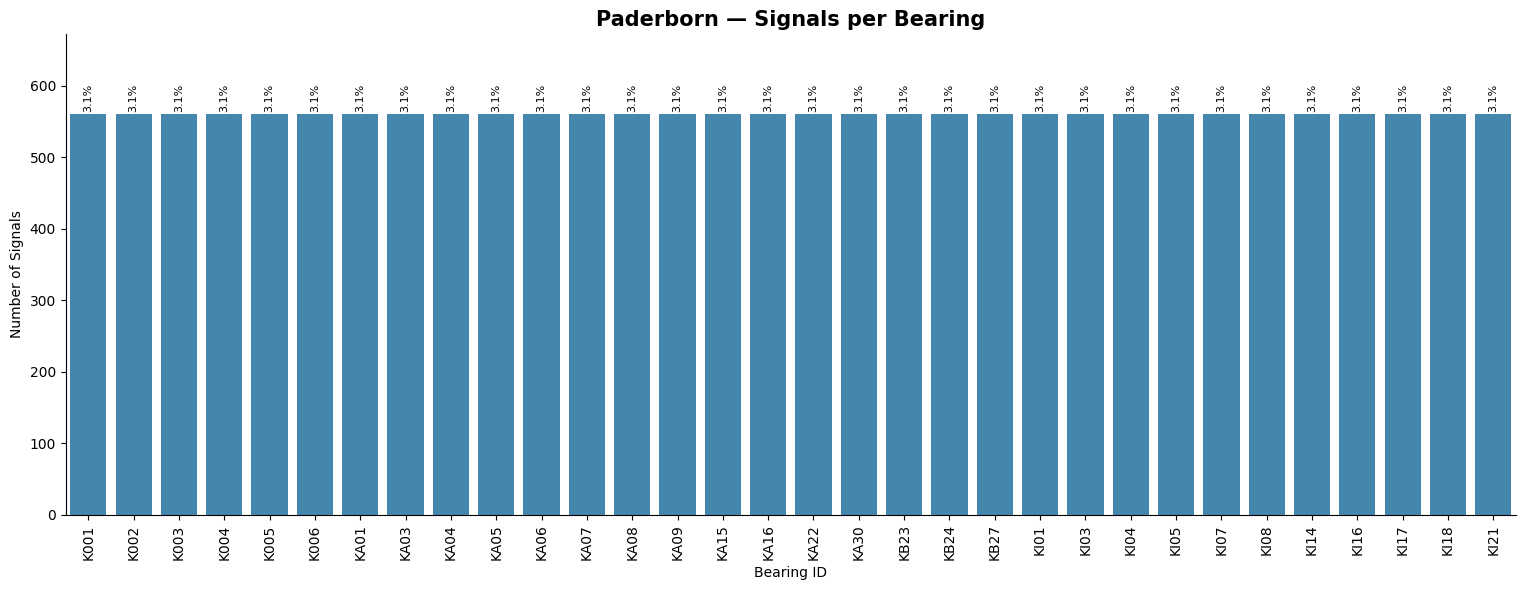

,bearing_id,n_signals,n_recordings,bearing_model,bpfo,bpfi,bsf,ftf
0,K001,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
1,K002,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
2,K003,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
3,K004,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
4,K005,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
5,K006,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
6,KA01,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
7,KA03,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]
8,KA04,560,80,6203,[3.05429],[4.94571],[1.9966],[0.38179]
9,KA05,560,80,6203,[3.07057],[4.92943],[2.03567],[0.38382]


In [28]:

df = paderborn_metadata_df

bearing_counts = df["bearing_id"].fillna("Unknown").value_counts()
percentages = bearing_counts / bearing_counts.sum() * 100

fig, ax = plt.subplots(
    figsize=(max(12, len(bearing_counts) * 0.48), 6)
)

sns.barplot(
    x=bearing_counts.index,
    y=bearing_counts.values,
    color="#348ABD",
    ax=ax
)

ax.set_title("Paderborn — Signals per Bearing", fontsize=15, weight="bold")
ax.set_xlabel("Bearing ID")
ax.set_ylabel("Number of Signals")
ax.tick_params(axis="x", rotation=90)

for i, (count, pct) in enumerate(zip(bearing_counts, percentages)):
    ax.text(
        i, count + bearing_counts.max() * 0.01,
        f"{pct:.1f}%",
        ha="center",
        fontsize=8,
        rotation=90
    )

ax.set_ylim(0, bearing_counts.max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

# One row per unique bearing/frequency combination
bearing_info = (
    df.groupby("bearing_id", dropna=False)
    .agg(
        n_signals=("signal_id", "count"),
        n_recordings=("recording_id", "nunique"),
        bearing_model=("bearing_model", lambda x: ", ".join(
            sorted(x.dropna().astype(str).unique())
        )),
        bpfo=("bpfo", lambda x: sorted(x.dropna().unique().tolist())),
        bpfi=("bpfi", lambda x: sorted(x.dropna().unique().tolist())),
        bsf=("bsf", lambda x: sorted(x.dropna().unique().tolist())),
        ftf=("ftf", lambda x: sorted(x.dropna().unique().tolist()))
    )
    .reset_index()
)

display(bearing_info)


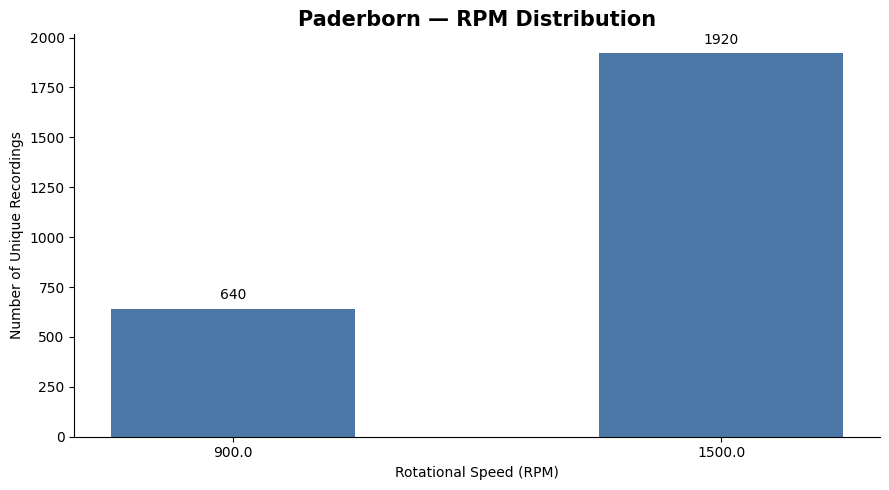

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

df = paderborn_metadata_df.copy()

# Select vibration recordings
df = df[df["channel"] == "vibration"]

# Remove duplicate recordings
df = df.drop_duplicates(subset=["recording_id"])

# Count unique recordings per RPM
rpm_counts = (
    df["speed_rpm"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    rpm_counts.index.astype(str),
    rpm_counts.values,
    width=0.5,
    color="#4C78A8"
)

ax.bar_label(bars, padding=5)

ax.set_title("Paderborn — RPM Distribution", fontsize=15, weight="bold")
ax.set_xlabel("Rotational Speed (RPM)")
ax.set_ylabel("Number of Unique Recordings")

sns.despine()
plt.tight_layout()
plt.show()

vibration: 2440/2560 recordings | Range: 256,000 – 264,362
phase_current_1: 2441/2560 recordings | Range: 256,000 – 264,362
phase_current_2: 2441/2560 recordings | Range: 256,000 – 264,362


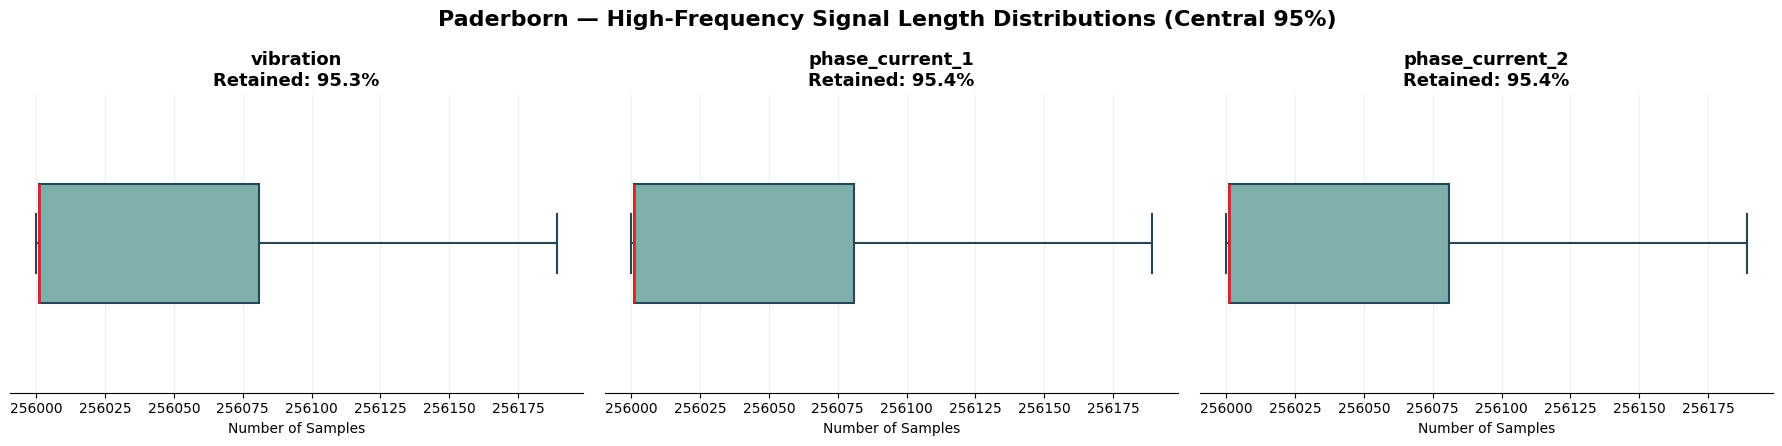

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = paderborn_metadata_df.copy()

channels = ["vibration", "phase_current_1", "phase_current_2"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for ax, channel in zip(axes, channels):

    values = df.loc[
        df["channel"] == channel, "n_samples"
    ].dropna()

    # Filter extreme values — central 95%
    lower = values.quantile(0.025)
    upper = values.quantile(0.975)

    filtered = values[values.between(lower, upper)]

    sns.boxplot(
        x=filtered,
        ax=ax,
        color="#76B7B2",
        width=0.4,
        linewidth=1.5,
        showfliers=False,
        boxprops={"edgecolor": "#264653"},
        whiskerprops={"color": "#264653"},
        capprops={"color": "#264653"},
        medianprops={"color": "#D62828", "linewidth": 2}
    )

    retention = len(filtered) / len(values) * 100

    ax.set_title(
        f"{channel}\nRetained: {retention:.1f}%",
        fontsize=13,
        weight="bold"
    )

    ax.set_xlabel("Number of Samples")
    ax.set_yticks([])
    ax.ticklabel_format(style="plain", axis="x")
    ax.grid(axis="x", alpha=0.2)

    sns.despine(ax=ax, left=True)

    print(
        f"{channel}: "
        f"{len(filtered)}/{len(values)} recordings | "
        f"Range: {filtered.min():,.0f} – {filtered.max():,.0f}"
    )

fig.suptitle(
    "Paderborn — High-Frequency Signal Length Distributions (Central 95%)",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()

In [14]:

df = paderborn_metadata_df.copy()

channels = ["force", "torque", "speed", "temperature"]

other = df[df["channel"].isin(channels)].copy()

median_samples = other.groupby("channel")["n_samples"].transform("median")

other["deviation_pct"] = (
    (other["n_samples"] - median_samples)
    / median_samples * 100
)




display(
    other.groupby("channel")["n_samples"]
    .agg(["count", "min", "median", "max", "std"])
    .round(2)
)


,count,min,median,max,std
channel,,,,,
force,2560,16000,16001.0,18691,57.71
speed,2560,16000,16001.0,18691,57.71
temperature,2560,4,5.0,5,0.23
torque,2560,16000,16001.0,18691,57.71


# Signals EDA

In [5]:
paderborn_signals_df.head()

,signal_id,signal
0,N09_M07_F10_K001_1/force,"[927.2627923316428, 919.9385735864832, 949.540..."
1,N09_M07_F10_K001_1/phase_current_1,"[-0.8726864618256157, -0.945697326035178, -1.0..."
2,N09_M07_F10_K001_1/phase_current_2,"[-1.1461328117425609, -1.2453173819895134, -1...."
3,N09_M07_F10_K001_1/speed,"[899.4742444862216, 899.4744255925016, 899.474..."
4,N09_M07_F10_K001_1/temperature,"[46.78039547689698, 47.00927731268321, 46.9879..."


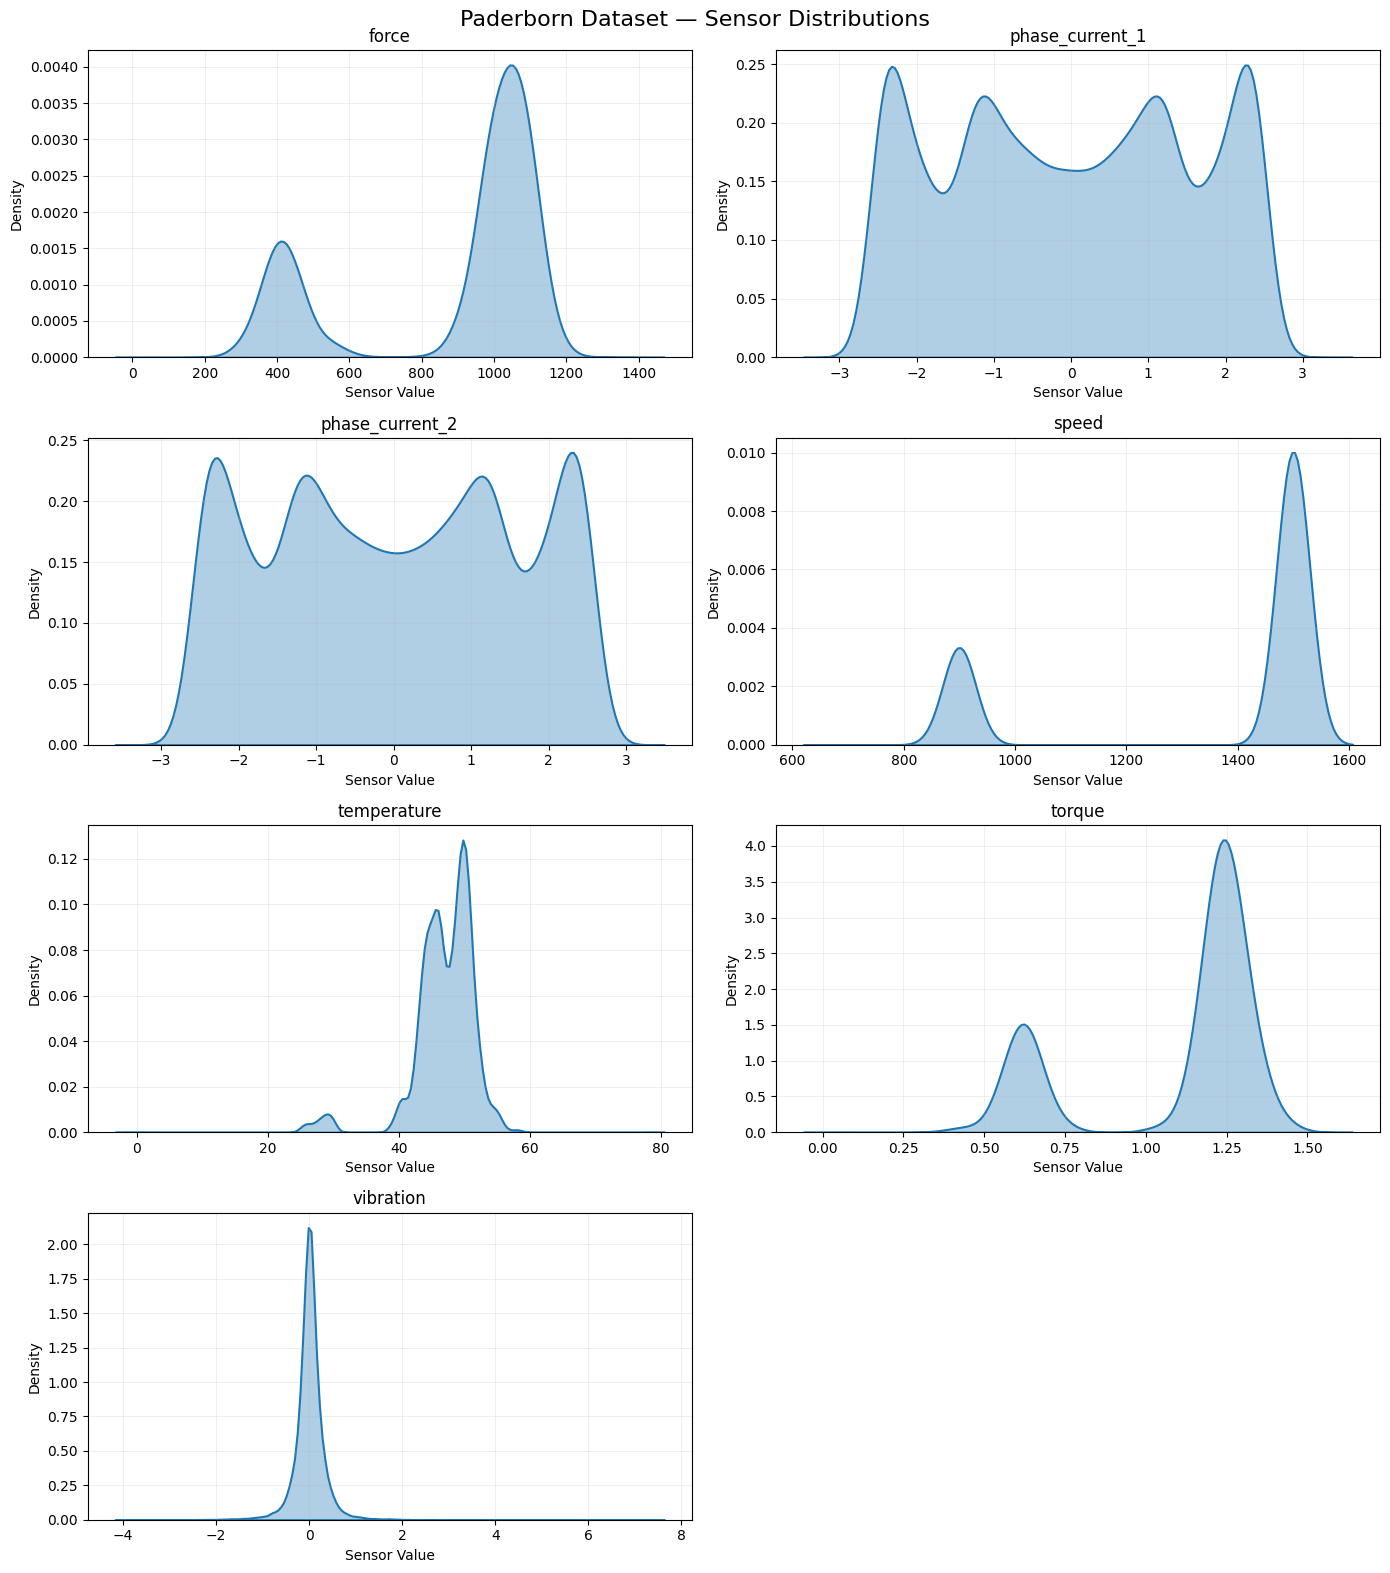

In [7]:

from math import ceil

df = paderborn_signals_df.copy()

# Extract sensor name from signal_id
df["sensor"] = df["signal_id"].str.split("/").str[-1]

# Convert each sensor's signal array into a long-form DataFrame
# Limit samples per sensor to keep KDE computation manageable
MAX_SAMPLES = 50_000
rng = np.random.default_rng(42)

sensor_data = {}

for sensor, group in df.groupby("sensor"):
    arrays = [
        np.asarray(signal, dtype=float).ravel()
        for signal in group["signal"]
    ]

    values = np.concatenate(arrays)
    values = values[np.isfinite(values)]

    if len(values) > MAX_SAMPLES:
        values = rng.choice(
            values,
            size=MAX_SAMPLES,
            replace=False
        )

    sensor_data[sensor] = values

# Create independent KDE plots
n_cols = 2
n_rows = ceil(len(sensor_data) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 4 * n_rows)
)

axes = np.atleast_1d(axes).ravel()

for ax, (sensor, values) in zip(axes, sensor_data.items()):

    if len(values) > 1 and np.std(values) > 0:
        sns.kdeplot(
            x=values,
            ax=ax,
            fill=True,
            alpha=0.35,
            linewidth=1.5
        )

    ax.set_title(sensor)
    ax.set_xlabel("Sensor Value")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

# Remove unused subplots
for ax in axes[len(sensor_data):]:
    ax.remove()

plt.suptitle(
    "Paderborn Dataset — Sensor Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [17]:

from scipy.stats import kurtosis

df = paderborn_signals_df.copy()

# Extract recording ID and channel
df[["recording_id", "channel"]] = (
    df["signal_id"].str.rsplit("/", n=1, expand=True)
)

# Keep only high-frequency diagnostic channels
channels = [
    "vibration",
    "phase_current_1",
    "phase_current_2"
]

df = df[df["channel"].isin(channels)].copy()

display(df.head())

,signal_id,signal,recording_id,channel
1,N09_M07_F10_K001_1/phase_current_1,"[-0.8726864618256157, -0.945697326035178, -1.0...",N09_M07_F10_K001_1,phase_current_1
2,N09_M07_F10_K001_1/phase_current_2,"[-1.1461328117425609, -1.2453173819895134, -1....",N09_M07_F10_K001_1,phase_current_2
6,N09_M07_F10_K001_1/vibration,"[0.0640869140201472, -0.122070312419328, 0.112...",N09_M07_F10_K001_1,vibration
8,N09_M07_F10_K001_10/phase_current_1,"[-0.7073788447473618, -0.7252871699308394, -0....",N09_M07_F10_K001_10,phase_current_1
9,N09_M07_F10_K001_10/phase_current_2,"[-1.431288451202549, -1.4863909902286336, -1.5...",N09_M07_F10_K001_10,phase_current_2


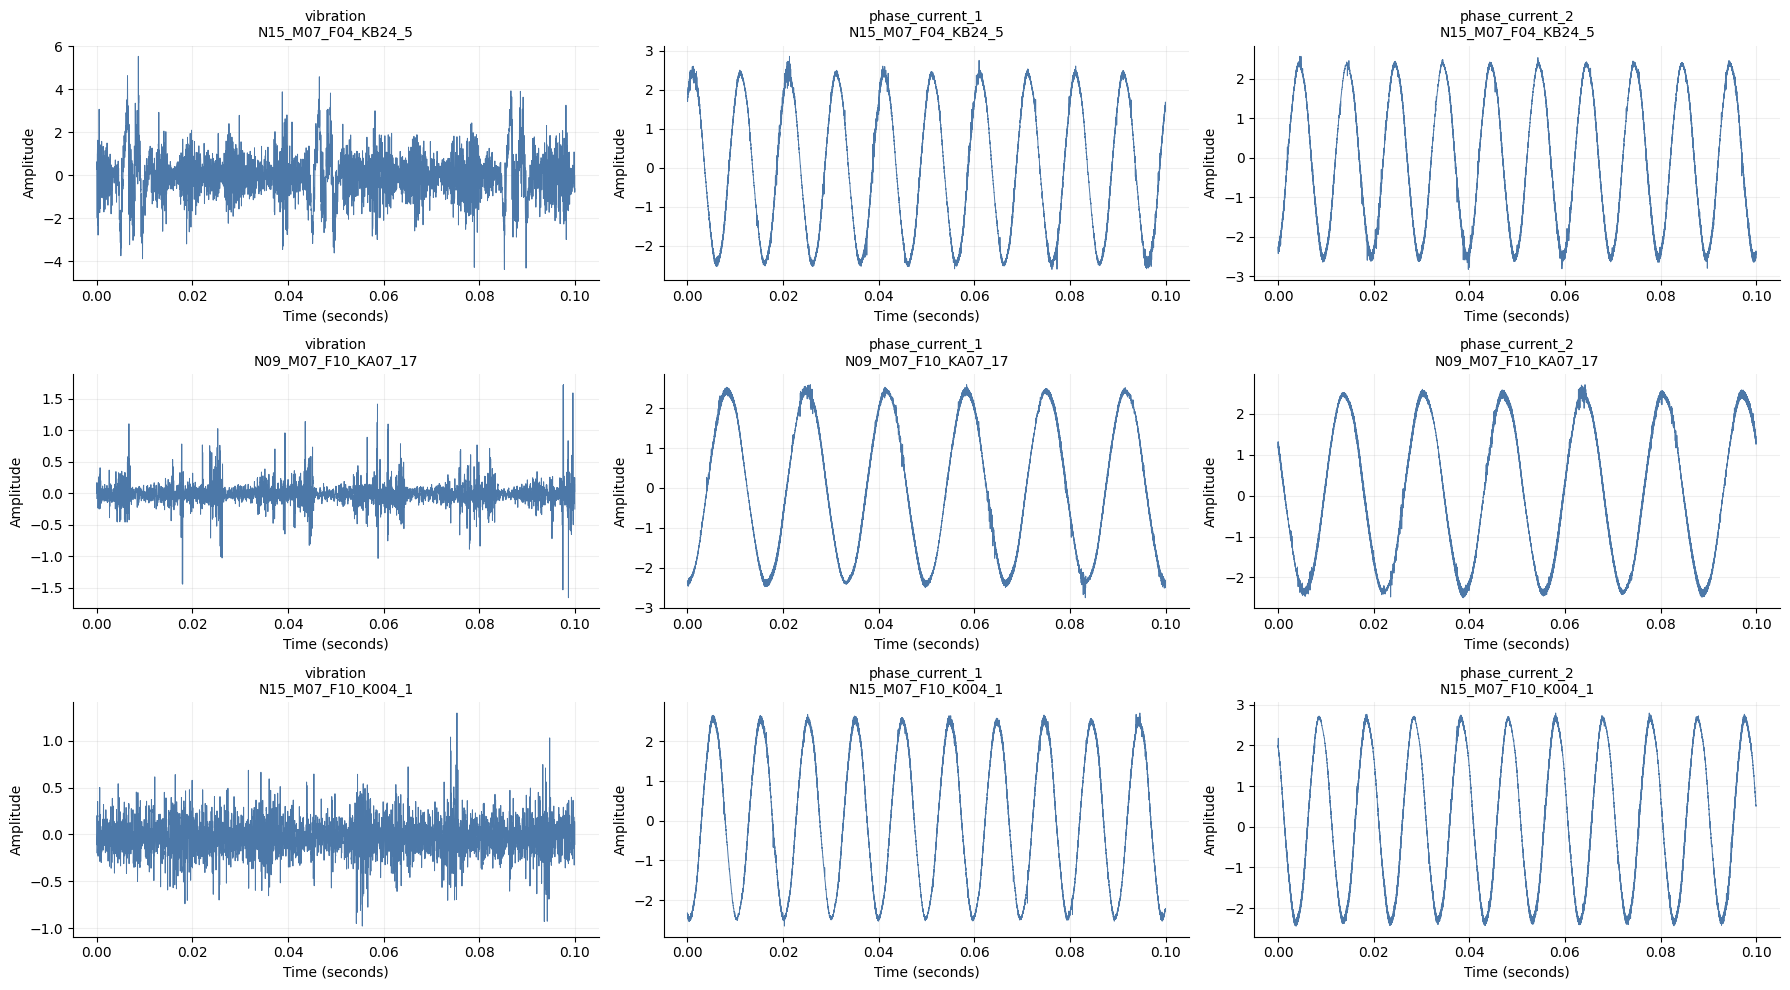

In [19]:
# Find recordings containing all three channels
valid_ids = (
    df.groupby("recording_id")["channel"]
      .nunique()
)

valid_ids = valid_ids[
    valid_ids == 3
].index.to_numpy()

# Randomly select 3 recordings
rng = np.random.default_rng(42)

selected_ids = rng.choice(
    valid_ids,
    size=3,
    replace=False
)

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 10)
)

# Known Paderborn high-frequency acquisition rate
fs = 64_000

# Plot the first 0.1 seconds for readability
PLOT_SECONDS = 0.1

for i, recording_id in enumerate(selected_ids):

    recording = df[df["recording_id"] == recording_id]

    for j, channel in enumerate(channels):

        signal = np.asarray(
            recording.loc[
                recording["channel"] == channel,
                "signal"
            ].iloc[0],
            dtype=float
        ).ravel()

        if PLOT_SECONDS is not None:
            signal = signal[:int(PLOT_SECONDS * fs)]

        time = np.arange(len(signal)) / fs

        ax = axes[i, j]

        ax.plot(
            time,
            signal,
            linewidth=0.7,
            color="#4C78A8"
        )

        ax.set_title(
            f"{channel}\n{recording_id}",
            fontsize=10
        )

        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")
        ax.grid(alpha=0.2)

sns.despine()
plt.tight_layout()
plt.show()

In [20]:
def extract_features(signal):

    x = np.asarray(signal, dtype=np.float64).ravel()
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return {
            "mean_amplitude": np.nan,
            "median_amplitude": np.nan,
            "rms": np.nan,
            "peak_amplitude": np.nan,
            "peak_to_peak": np.nan,
            "std": np.nan,
            "crest_factor": np.nan,
            "kurtosis": np.nan
        }

    rms = np.sqrt(np.mean(x ** 2))
    peak = np.max(np.abs(x))

    return {
        "mean_amplitude": np.mean(x),
        "median_amplitude": np.median(x),
        "rms": rms,
        "peak_amplitude": peak,
        "peak_to_peak": np.ptp(x),
        "std": np.std(x),
        "crest_factor": peak / rms if rms > 0 else np.nan,
        "kurtosis": kurtosis(x, fisher=False)
    }


features = []

for row in df.itertuples(index=False):

    result = extract_features(row.signal)

    result["recording_id"] = row.recording_id
    result["channel"] = row.channel

    features.append(result)

features_df = pd.DataFrame(features)

# Aggregate features across recordings
summary = (
    features_df
    .groupby("channel")
    .agg({
        col: ["mean", "median"]
        for col in [
            "mean_amplitude",
            "median_amplitude",
            "rms",
            "peak_amplitude",
            "peak_to_peak",
            "std",
            "crest_factor",
            "kurtosis"
        ]
    })
    .round(4)
)

display(summary)

mean_amplitude         median_amplitude             rms  \
                          mean  median             mean  median    mean   
channel                                                                   
phase_current_1        -0.0238 -0.0238          -0.0260 -0.0255  1.5264   
phase_current_2         0.0072 -0.0049           0.0045 -0.0062  1.5381   
vibration               0.0070 -0.0106           0.0079 -0.0092  0.3067   

                        peak_amplitude         peak_to_peak             std  \
                 median           mean  median         mean  median    mean   
channel                                                                       
phase_current_1  1.7202         2.7093  2.9631       5.3267  5.8422  1.5259   
phase_current_2  1.7331         2.8068  2.9611       5.3736  5.7217  1.5365   
vibration        0.2504         3.2489  3.1006       6.0612  5.8029  0.3049   

                        crest_factor          kurtosis          
                 median         mean   median     mean  median  
channel                                                         
phase_current_1  1.7199       1.8090   1.7374   1.5055  1.5053  
phase_current_2  1.7305       1.8641   1.7930   1.5102  1.5080  
vibration        0.2483      11.0542  10.6587  11.0138  8.3859

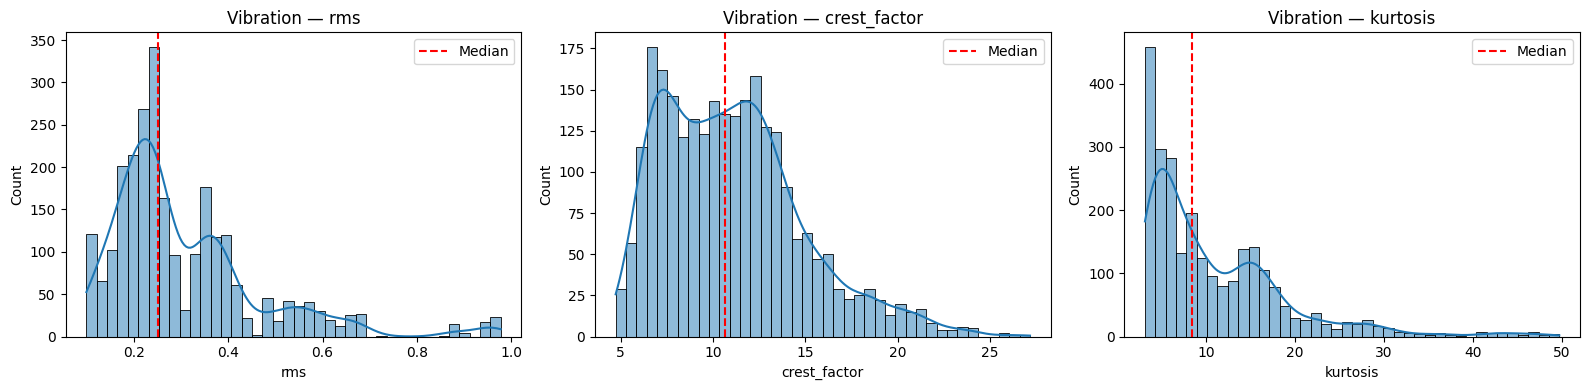

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Only vibration features
vibration = features_df[
    features_df["channel"] == "vibration"
].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = ["rms", "crest_factor", "kurtosis"]

for ax, metric in zip(axes, metrics):
    sns.histplot(
        data=vibration,
        x=metric,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(
        vibration[metric].median(),
        color="red",
        linestyle="--",
        label="Median"
    )

    ax.set_title(f"Vibration — {metric}")
    ax.legend()

plt.tight_layout()
plt.show()

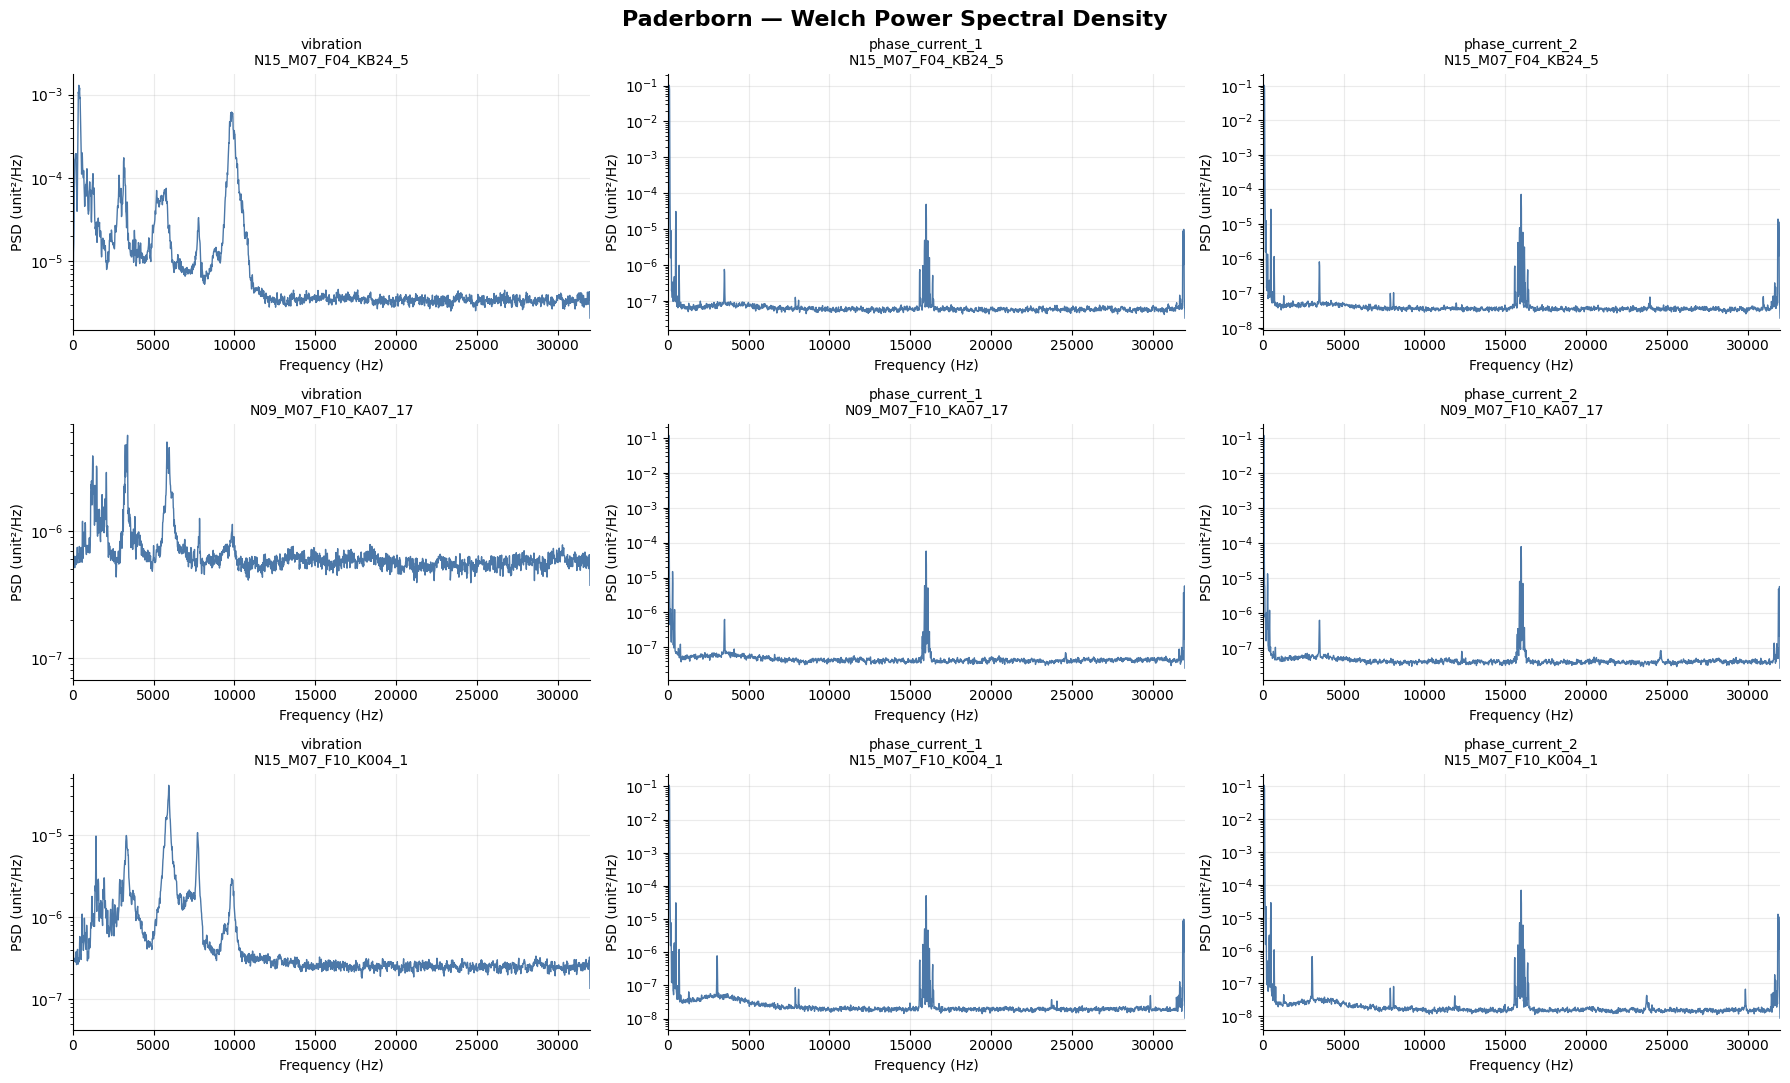

In [23]:

from scipy.signal import welch

df = paderborn_signals_df.copy()

df[["recording_id", "channel"]] = (
    df["signal_id"].str.rsplit("/", n=1, expand=True)
)

channels = [
    "vibration",
    "phase_current_1",
    "phase_current_2"
]

df = df[df["channel"].isin(channels)].copy()

# Recordings containing all three channels
valid_ids = (
    df.groupby("recording_id")["channel"]
    .nunique()
)

valid_ids = valid_ids[
    valid_ids == len(channels)
].index.to_numpy()

rng = np.random.default_rng(42)

selected_ids = rng.choice(
    valid_ids,
    size=3,
    replace=False
)

# Nominal Paderborn high-frequency sampling rate
fs = 64_000

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 11)
)

for i, recording_id in enumerate(selected_ids):

    recording = df[df["recording_id"] == recording_id]

    for j, channel in enumerate(channels):

        signal = np.asarray(
            recording.loc[
                recording["channel"] == channel,
                "signal"
            ].iloc[0],
            dtype=np.float64
        ).ravel()

        frequencies, psd = welch(
            signal,
            fs=fs,
            window="hann",
            nperseg=4096,
            noverlap=2048,
            detrend="constant",
            scaling="density"
        )

        ax = axes[i, j]

        ax.semilogy(
            frequencies,
            psd,
            linewidth=1,
            color="#4C78A8"
        )

        ax.set_title(
            f"{channel}\n{recording_id}",
            fontsize=10
        )

        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel("PSD (unit²/Hz)")
        ax.set_xlim(0, fs / 2)
        ax.grid(alpha=0.25)

fig.suptitle(
    "Paderborn — Welch Power Spectral Density",
    fontsize=16,
    weight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()

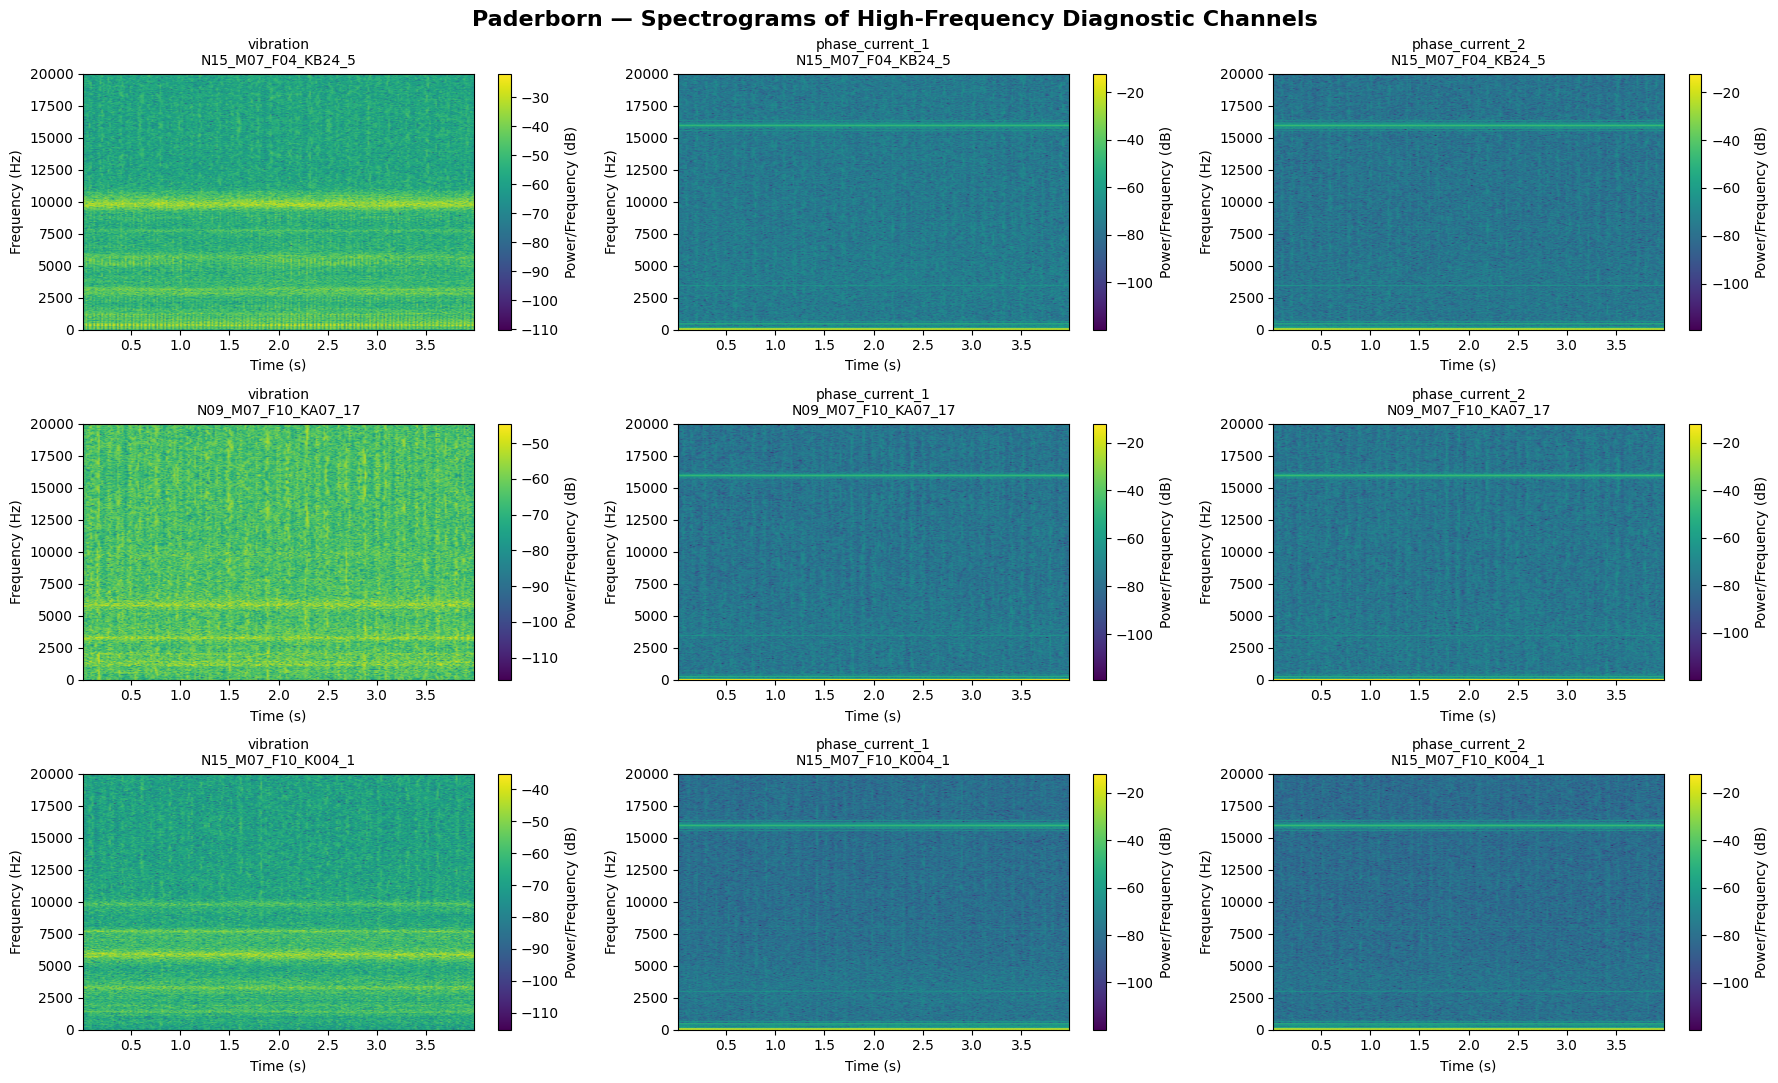

In [24]:

from scipy.signal import spectrogram

df = paderborn_signals_df.copy()

# Extract recording id and channel from signal_id
df[["recording_id", "channel"]] = (
    df["signal_id"].str.rsplit("/", n=1, expand=True)
)

channels = ["vibration", "phase_current_1", "phase_current_2"]
df = df[df["channel"].isin(channels)].copy()

# Keep only recordings that contain all 3 channels
valid_ids = (
    df.groupby("recording_id")["channel"]
      .nunique()
)
valid_ids = valid_ids[valid_ids == len(channels)].index.to_numpy()

# Randomly select 3 recordings
rng = np.random.default_rng(42)
selected_ids = rng.choice(valid_ids, size=3, replace=False)

# Nominal sampling frequency for high-frequency channels
fs = 64_000

fig, axes = plt.subplots(3, 3, figsize=(18, 11))

for i, recording_id in enumerate(selected_ids):
    rec = df[df["recording_id"] == recording_id]

    for j, channel in enumerate(channels):
        signal = np.asarray(
            rec.loc[rec["channel"] == channel, "signal"].iloc[0],
            dtype=np.float64
        ).ravel()

        # STFT / spectrogram
        f, t, Sxx = spectrogram(
            signal,
            fs=fs,
            window="hann",
            nperseg=2048,
            noverlap=1024,
            detrend="constant",
            scaling="density",
            mode="psd"
        )

        # Convert power to dB for readability
        Sxx_db = 10 * np.log10(Sxx + 1e-12)

        ax = axes[i, j]

        mesh = ax.pcolormesh(
            t, f, Sxx_db,
            shading="gouraud",
            cmap="viridis"
        )

        ax.set_title(f"{channel}\n{recording_id}", fontsize=10)
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Frequency (Hz)")

        # Limit to a useful frequency range for readability
        ax.set_ylim(0, 20000)

        cbar = fig.colorbar(mesh, ax=ax)
        cbar.set_label("Power/Frequency (dB)")

fig.suptitle(
    "Paderborn — Spectrograms of High-Frequency Diagnostic Channels",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()
plt.show()

In [38]:
paderborn_signals_df.iloc[0:,1:].to_numpy()[0]

array([array([927.26279233, 919.93857359, 949.54062435, ..., 927.56796811,
              929.3990228 , 927.87314389])                                ],
      dtype=object)

In [53]:
vibration_df = paderborn_signals_df.loc[
    paderborn_signals_df["signal_id"].str.endswith("/vibration", na=False)
].copy()

print("Vibration signals:", len(vibration_df))
print(vibration_df.head())

Vibration signals: 2560
                        signal_id  \
6    N09_M07_F10_K001_1/vibration   
13  N09_M07_F10_K001_10/vibration   
20  N09_M07_F10_K001_11/vibration   
27  N09_M07_F10_K001_12/vibration   
34  N09_M07_F10_K001_13/vibration   

                                               signal  
6   [0.0640869140201472, -0.122070312419328, 0.112...  
13  [0.0213623046733824, -0.10681152336691199, -0....  
20  [-0.274658202943488, 0.033569335915315204, 1.1...  
27  [-0.1892089842499584, -0.0823974608830464, -0....  
34  [-0.0640869140201472, -0.0396728515362816, 0.0...  


SIGNAL LENGTH DISTRIBUTION
count      2560.00
mean     256725.25
std        3723.97
min      190937.00
1%       255999.00
5%       256000.00
50%      256001.00
95%      259356.50
99%      277345.02
max      299038.00
Name: signal, dtype: float64

DISTANCE FROM TARGET
Target length                            256000.0000
Recordings needing padding (%)                2.1875
Recordings already at target (%)             12.8906
Recordings needing trimming (%)              84.9219
Mean absolute difference (samples)          785.0969
95th percentile absolute difference        3494.6500
Maximum padding needed (samples)          65063.0000
Maximum trimming needed (samples)         43038.0000
Original samples removed overall (%)          0.2942
Padding as fraction of final data (%)         0.0117
dtype: float64

10 RECORDINGS FARTHEST FROM TARGET
       n_samples  difference  absolute_difference  difference_pct  \
6943      190937      -65063                65063        -25.4152   
15924     299

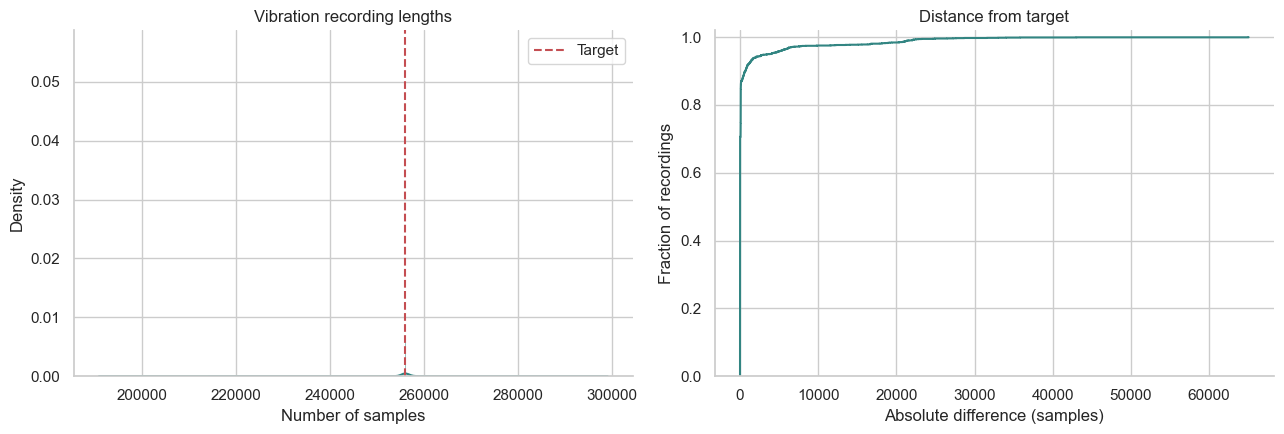

In [54]:

# Change this to the verified vibration column name.
SIGNAL_COLUMN = 'signal'
TARGET_LENGTH = 256_000

# Assumes each cell contains one 1D waveform.
signals = vibration_df["signal"]

# Check structure before calculating lengths.
if not signals.map(lambda x: np.asarray(x).ndim == 1).all():
    raise ValueError("Some cells are not 1D signals. Inspect their structure first.")

lengths = signals.map(len).astype("int64")

if lengths.empty or (lengths == 0).any():
    raise ValueError("The selected column is empty or contains empty signals.")

# Negative difference = needs padding; positive = needs trimming.
stats = pd.DataFrame({"n_samples": lengths})
stats["difference"] = stats["n_samples"] - TARGET_LENGTH
stats["absolute_difference"] = stats["difference"].abs()
stats["difference_pct"] = 100 * stats["difference"] / TARGET_LENGTH
stats["pad_samples"] = (-stats["difference"]).clip(lower=0)
stats["trim_samples"] = stats["difference"].clip(lower=0)

print("SIGNAL LENGTH DISTRIBUTION")
print(
    lengths.describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    ).round(2)
)

summary = pd.Series({
    "Target length": TARGET_LENGTH,
    "Recordings needing padding (%)": 100 * (stats["difference"] < 0).mean(),
    "Recordings already at target (%)": 100 * (stats["difference"] == 0).mean(),
    "Recordings needing trimming (%)": 100 * (stats["difference"] > 0).mean(),
    "Mean absolute difference (samples)": stats["absolute_difference"].mean(),
    "95th percentile absolute difference": stats["absolute_difference"].quantile(0.95),
    "Maximum padding needed (samples)": stats["pad_samples"].max(),
    "Maximum trimming needed (samples)": stats["trim_samples"].max(),
    "Original samples removed overall (%)":
        100 * stats["trim_samples"].sum() / lengths.sum(),
    "Padding as fraction of final data (%)":
        100 * stats["pad_samples"].sum() / (len(stats) * TARGET_LENGTH),
})

print("\nDISTANCE FROM TARGET")
print(summary.round(4))

print("\n10 RECORDINGS FARTHEST FROM TARGET")
print(stats.nlargest(10, "absolute_difference").round(4))

# Clean plots: actual lengths and deviations from the target.
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(
    x=lengths,
    bins="auto",
    stat="density",
    kde=lengths.nunique() > 1,
    color="#328582",
    edgecolor="white",
    ax=axes[0],
)
axes[0].axvline(
    TARGET_LENGTH, color="#c44e52", linestyle="--", label="Target"
)
axes[0].set(
    title="Vibration recording lengths",
    xlabel="Number of samples",
    ylabel="Density",
)
axes[0].legend()

sns.ecdfplot(
    x=stats["absolute_difference"],
    color="#328582",
    ax=axes[1],
)
axes[1].set(
    title="Distance from target",
    xlabel="Absolute difference (samples)",
    ylabel="Fraction of recordings",
    ylim=(0, 1.02),
)

for ax in axes:
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)

sns.despine()
plt.tight_layout()
plt.show()